In [6]:
import sys
sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.db import read_sql
from src.cleaning import load_clean_orders
sns.set_theme(style='whitegrid')

monthly = read_sql('''
SELECT DATE_TRUNC('month', order_purchase_timestamp) AS month,
       SUM(payment_total) AS revenue, COUNT(*) AS orders
FROM vw_orders_clean GROUP BY 1 ORDER BY 1
''')

q11 = '''
WITH ranked AS (
  SELECT customer_unique_id, delivery_delay_days,
         ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY order_purchase_timestamp) AS rn
  FROM vw_orders_clean
)
SELECT CASE WHEN r.delivery_delay_days <= 0 THEN '1 On time or early'
            WHEN r.delivery_delay_days <= 3 THEN '2 Late 1-3 days'
            WHEN r.delivery_delay_days <= 7 THEN '3 Late 4-7 days'
            ELSE '4 Late 7+ days' END AS delay_bucket,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(CASE WHEN c.n_orders > 1 THEN 1 ELSE 0 END), 2) AS repeat_rate_pct
FROM ranked r
JOIN vw_customer_orders c ON c.customer_unique_id = r.customer_unique_id
WHERE r.rn = 1
GROUP BY 1 ORDER BY 1
'''
delay = read_sql(q11)
delay

,delay_bucket,customers,repeat_rate_pct
0,1 On time or early,86993,3.03
1,2 Late 1-3 days,1821,2.42
2,3 Late 4-7 days,1749,2.40
3,4 Late 7+ days,2787,2.73


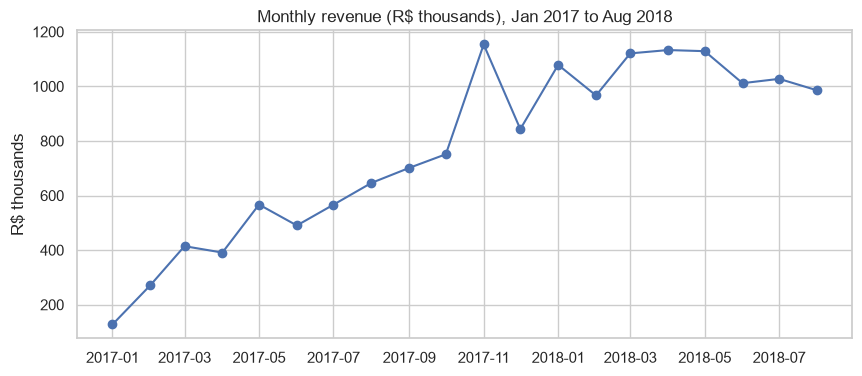

In [7]:
monthly['month'] = pd.to_datetime(monthly['month'])
m = monthly[(monthly['month'] >= '2017-01-01') & (monthly['month'] <= '2018-08-01')]
plt.figure(figsize=(10, 4))
plt.plot(m['month'], m['revenue'] / 1000, marker='o')
plt.title('Monthly revenue (R$ thousands), Jan 2017 to Aug 2018')
plt.ylabel('R$ thousands')
plt.savefig('../reports/figures/final_monthly_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

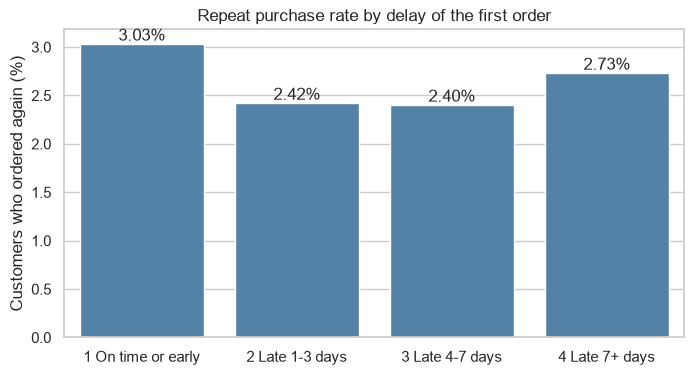

In [8]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=delay, x='delay_bucket', y='repeat_rate_pct', color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.2f%%')
plt.title('Repeat purchase rate by delay of the first order')
plt.xlabel(''); plt.ylabel('Customers who ordered again (%)')
plt.savefig('../reports/figures/final_repeat_by_delay.png', dpi=150, bbox_inches='tight')
plt.show()

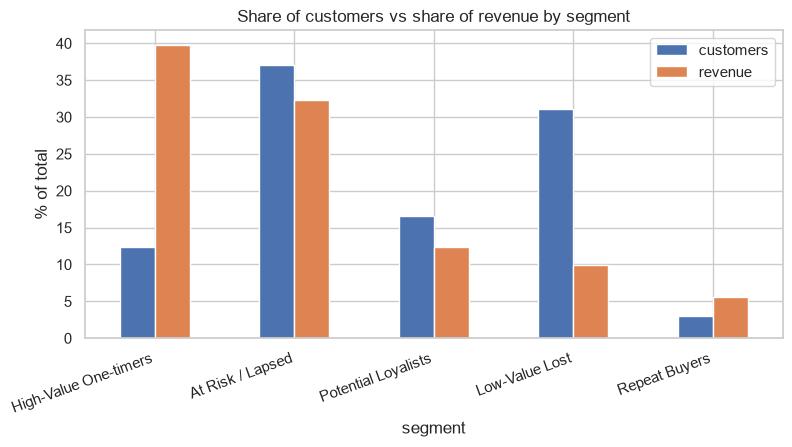

In [9]:
rfm = pd.read_csv('../data/processed/customer_rfm.csv')
seg = rfm.groupby('segment').agg(customers=('customer_unique_id', 'count'), revenue=('monetary', 'sum'))
seg = (seg / seg.sum() * 100).sort_values('revenue', ascending=False)
seg.plot(kind='bar', figsize=(9, 4), title='Share of customers vs share of revenue by segment')
plt.ylabel('% of total'); plt.xticks(rotation=20, ha='right')
plt.savefig('../reports/figures/final_segments.png', dpi=150, bbox_inches='tight')
plt.show()

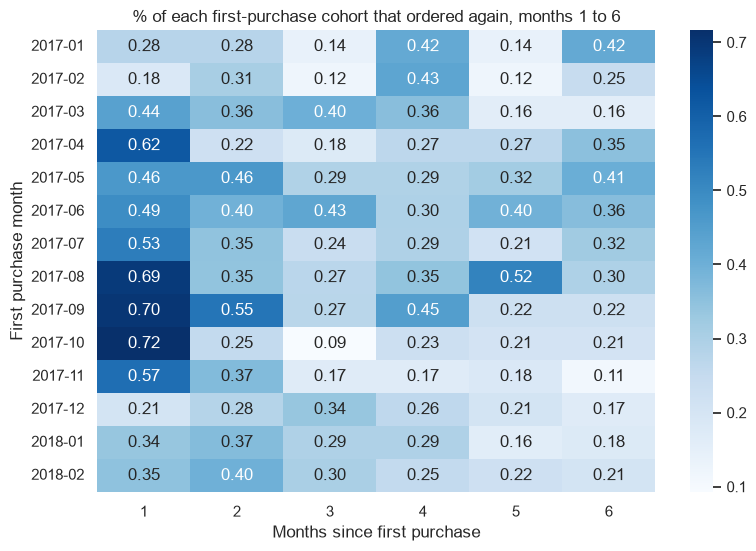

In [10]:
df = load_clean_orders()
first = df.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min')
df['month_index'] = ((df['order_purchase_timestamp'].dt.year - first.dt.year) * 12
                     + (df['order_purchase_timestamp'].dt.month - first.dt.month))
df['cohort'] = first.dt.to_period('M')
c = df.groupby(['cohort', 'month_index'])['customer_unique_id'].nunique().unstack(fill_value=0)
ret = (c.div(c[0], axis=0) * 100).loc['2017-01':'2018-02', 1:6]
plt.figure(figsize=(9, 6))
sns.heatmap(ret, annot=True, fmt='.2f', cmap='Blues')
plt.title('% of each first-purchase cohort that ordered again, months 1 to 6')
plt.ylabel('First purchase month'); plt.xlabel('Months since first purchase')
plt.savefig('../reports/figures/final_cohort_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()